In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── Sklearn ─────────────────────────────────────────────────────
from sklearn.linear_model       import LinearRegression
from sklearn.ensemble           import RandomForestRegressor
from sklearn.neural_network     import MLPRegressor
from sklearn.preprocessing      import StandardScaler
from sklearn.metrics            import mean_squared_error, mean_absolute_error, r2_score

# ── XGBoost ─────────────────────────────────────────────────────
from xgboost import XGBRegressor

# ── Deep Learning ───────────────────────────────────────────────
from tensorflow.keras.models    import Sequential
from tensorflow.keras.layers    import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

In [3]:
df = pd.read_csv(r'E:\2025.2\DAV\data\Power_solar_Bacgiang.csv')
RANDOM_STATE = 42
NIGHT_FILTER = True
SZA_THRESHOLD = 90
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52601 entries, 0 to 52600
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime_vn         52601 non-null  str    
 1   year                52601 non-null  int64  
 2   month               52601 non-null  int64  
 3   day                 52601 non-null  int64  
 4   hour                52601 non-null  int64  
 5   T2M                 52601 non-null  float64
 6   RH2M                52601 non-null  float64
 7   PRECTOTCORR         52601 non-null  float64
 8   T2MDEW              52601 non-null  float64
 9   WS10M               52601 non-null  float64
 10  WD10M               52601 non-null  float64
 11  ALLSKY_SRF_ALB      52601 non-null  float64
 12  ALLSKY_SFC_SW_DWN   52601 non-null  float64
 13  ALLSKY_SFC_SW_DNI   52601 non-null  float64
 14  ALLSKY_SFC_SW_DIFF  52601 non-null  float64
 15  ALLSKY_KT           52601 non-null  float64
 16  SZA            

In [4]:
if NIGHT_FILTER:
    df_day = df[df['SZA'] < SZA_THRESHOLD].copy()
    df_day.reset_index(drop=True, inplace=True)
    print(f"\n[NIGHT_FILTER = True]")
    print(f"Trước lọc : {len(df):,} rows")
    print(f"Sau lọc   : {len(df_day):,} rows")
    print(f"Đã loại   : {len(df) - len(df_day):,} rows ban đêm "
          f"({(len(df) - len(df_day)) / len(df) * 100:.1f}%)")
else:
    df_day = df.copy()
    print(f"\n[NIGHT_FILTER = False] Giữ toàn bộ {len(df_day):,} rows")

print(f"\nShape sau xử lý: {df_day.shape}")


[NIGHT_FILTER = True]
Trước lọc : 52,601 rows
Sau lọc   : 27,453 rows
Đã loại   : 25,148 rows ban đêm (47.8%)

Shape sau xử lý: (27453, 18)


In [5]:
ISC = 1367  # Hằng số mặt trời (W/m²)

LEAKAGE_COLS = [
    'ALLSKY_SFC_SW_DWN',   # chính là GHI → target gián tiếp
    'ALLSKY_SFC_SW_DNI',   # tính từ GHI
    'ALLSKY_SFC_SW_DIFF',  # tính từ GHI
    'ALLSKY_SRF_ALB',      # phụ thuộc GHI
]

FEATURES = [
    # Thời gian
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    # Khí tượng
    'T2M', 'RH2M', 'PRECTOTCORR',
    # Gió
    'WS10M',
    # Bức xạ
    'SZA', 'H0', 'CLRSKY_SFC_SW_DWN'
]

TARGET = 'ALLSKY_KT'

def feature_engineering(df: pd.DataFrame) -> pd.DataFrame:

    df = df.copy()

    # ── 1. Lưu GHI actual (trước khi drop) ─────────────────────
    df['GHI_actual'] = df['ALLSKY_SFC_SW_DWN']

    # ── 2. Cyclic encoding ──────────────────────────────────────
    df['hour_sin']  = np.sin(2 * np.pi * df['hour']  / 24)
    df['hour_cos']  = np.cos(2 * np.pi * df['hour']  / 24)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

    # ── 3. Tính H0 ──────────────────────────────────────────────
    df['day_of_year'] = pd.to_datetime(df[['year', 'month', 'day']]).dt.dayofyear
    df['H0'] = df['GHI_actual'] / df['ALLSKY_KT']
    df['H0']  = df['H0'].clip(lower=0)

    # ── 4. Drop leakage columns ─────────────────────────────────
    df.drop(columns=LEAKAGE_COLS, inplace=True)


    print("=" * 50)
    print(f"Feature Engineering hoàn tất")
    print(f"Shape          : {df.shape}")
    print(f"Features ({len(FEATURES)}): {FEATURES}")
    print(f"Target         : {TARGET}")
    print(f"\nThống kê target ({TARGET}):")
    print(df[TARGET].describe().round(3))
    print("=" * 50)

    return df

# ════════════════════════════════════════════════════════════════
# Chạy
# ════════════════════════════════════════════════════════════════
df_fe = feature_engineering(df_day)

Feature Engineering hoàn tất
Shape          : (27453, 21)
Features (11): ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M', 'SZA', 'H0', 'CLRSKY_SFC_SW_DWN']
Target         : ALLSKY_KT

Thống kê target (ALLSKY_KT):
count    27453.000
mean         0.347
std          0.176
min          0.010
25%          0.200
50%          0.320
75%          0.490
max          0.780
Name: ALLSKY_KT, dtype: float64


In [6]:
# ── CONFIG ──────────────────────────────────────────────────────
FEATURES = [
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos','day',
    'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M',
    'SZA', 'H0', 'CLRSKY_SFC_SW_DWN'
]
TARGET = 'ALLSKY_KT'

# ════════════════════════════════════════════════════════════════
# Split
# ════════════════════════════════════════════════════════════════
def train_val_test_split(df: pd.DataFrame):
    df = df.copy()
    df['datetime_vn'] = pd.to_datetime(df['datetime_vn'])

    train_mask = (df['datetime_vn'] >= '2020-01-01') & (df['datetime_vn'] < '2025-03-01')
    val_mask   = (df['datetime_vn'] >= '2025-03-01') & (df['datetime_vn'] < '2025-09-01')
    test_mask  =  df['datetime_vn'] >= '2025-09-01'

    train = df[train_mask]
    val   = df[val_mask]
    test  = df[test_mask]

    X_train = train[FEATURES].values
    y_train = train[TARGET].values
    X_val   = val[FEATURES].values
    y_val   = val[TARGET].values
    X_test  = test[FEATURES].values
    y_test  = test[TARGET].values

    H0_val   = val['H0'].values        # ← thêm
    GHI_val  = val['GHI_actual'].values  # ← thêm
    H0_test  = test['H0'].values
    GHI_test = test['GHI_actual'].values

    return (X_train, X_val, X_test,
            y_train, y_val, y_test,
            H0_val, GHI_val,          # ← thêm
            H0_test, GHI_test)

X_train, X_val, X_test, \
y_train, y_val, y_test, \
H0_val, GHI_val,         \
H0_test, GHI_test = train_val_test_split(df_fe)

# ── Scaler (dùng cho MLP và LSTM) ───────────────────────────────
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

len(X_train)
len(X_val)


2457

In [7]:
def evaluate_kt(name, y_true, y_pred):
    # ── Metrics cơ bản ───────────────────────────────────────────
    rmse  = np.sqrt(mean_squared_error(y_true, y_pred))
    mae   = mean_absolute_error(y_true, y_pred)
    r2    = r2_score(y_true, y_pred)



    # ── Paper 2: rRMSE, rMAE (normalize theo mean) ──────────────
    # Về công thức tương đương NRMSE nhưng Paper 2 gọi là relative
    rrmse = rmse / np.mean(y_true)                  # dimensionless


    # ── Paper 3: MAPE, MBE ──────────────────────────────────────
    mape  = np.mean(np.abs((y_true - y_pred)
                           / (y_true + 1e-6))) * 100  # %
    print(
        f"{name:20s} | "
        f"RMSE={rmse:.4f} | MAE={mae:.4f} | R²={r2:.4f} | "

        f"rRMSE={rrmse:.4f} | "  # Paper 2
        f"MAPE={mape:.2f}% | "       # Paper 3
    )

    return {
        'Model' : name,
        # Cơ bản
        'RMSE'  : rmse,
        'MAE'   : mae,
        'R2'    : r2,
       
        # Paper 2
        'rRMSE' : rrmse,

        # Paper 3
        'MAPE(%)' : mape,
    
    }

results = []

In [8]:
lr = LinearRegression()
lr.fit(X_train_sc, y_train)
pred_lr = lr.predict(X_test_sc)
results.append(evaluate_kt("LinearRegression", y_test, pred_lr))

LinearRegression     | RMSE=0.1147 | MAE=0.0919 | R²=0.5988 | rRMSE=0.3009 | MAPE=32.89% | 


In [9]:
rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(evaluate_kt("RandomForest", y_test, pred_rf))

RandomForest         | RMSE=0.1003 | MAE=0.0799 | R²=0.6928 | rRMSE=0.2633 | MAPE=27.96% | 


In [10]:
xgb = XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    )
xgb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
pred_xgb = xgb.predict(X_test)
results.append(evaluate_kt("XGBoost", y_test, pred_xgb))

XGBoost              | RMSE=0.0978 | MAE=0.0778 | R²=0.7083 | rRMSE=0.2566 | MAPE=27.39% | 


In [11]:
mlp = MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=RANDOM_STATE
    )
mlp.fit(X_train_sc, y_train)
pred_mlp = mlp.predict(X_test_sc)
results.append(evaluate_kt("MLP", y_test, pred_mlp))

MLP                  | RMSE=0.1041 | MAE=0.0817 | R²=0.6694 | rRMSE=0.2731 | MAPE=29.34% | 


In [12]:
def create_sequences(X, y, window=12):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

WINDOW = 12
X_train_seq, y_train_seq = create_sequences(X_train_sc, y_train, WINDOW)
X_val_seq,   y_val_seq   = create_sequences(X_val_sc,   y_val,   WINDOW)
X_test_seq,  y_test_seq  = create_sequences(X_test_sc,  y_test,  WINDOW)

lstm_model = Sequential([
    LSTM(64, input_shape=(WINDOW, X_train_sc.shape[1]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)
lstm_model.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=100,
    batch_size=256,
    callbacks=[es],
    verbose=0
)
pred_lstm = lstm_model.predict(X_test_seq, verbose=0).flatten()
results.append(evaluate_kt("LSTM", y_test_seq, pred_lstm))

LSTM                 | RMSE=0.1060 | MAE=0.0826 | R²=0.6589 | rRMSE=0.2784 | MAPE=29.28% | 


In [13]:
results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)

print("\n══ Model Comparison (KT — Test Set) ══")
print(results_df.to_string(index=False))
print(f"\n✅ Best model: {results_df.iloc[0]['Model']}")


══ Model Comparison (KT — Test Set) ══
           Model     RMSE      MAE       R2    rRMSE   MAPE(%)
         XGBoost 0.097775 0.077844 0.708343 0.256553 27.387863
    RandomForest 0.100349 0.079928 0.692782 0.263308 27.955835
             MLP 0.104093 0.081667 0.669430 0.273132 29.342452
            LSTM 0.105962 0.082632 0.658924 0.278437 29.283620
LinearRegression 0.114674 0.091933 0.598814 0.300894 32.886392

✅ Best model: XGBoost


In [14]:
def recover_ghi(kt_pred: np.ndarray, H0: np.ndarray) -> np.ndarray:
    """
    Tính GHI từ K_T predicted và H0.
        GHI = clip(K_T, 0, 1) × H0
    """
    kt_clipped = np.clip(kt_pred, 0, 1)
    return kt_clipped * H0

def evaluate_ghi(name, ghi_true, ghi_pred):
    rmse = np.sqrt(mean_squared_error(ghi_true, ghi_pred))
    mae  = mean_absolute_error(ghi_true, ghi_pred)
    r2   = r2_score(ghi_true, ghi_pred)
    mape = np.mean(np.abs((ghi_true - ghi_pred) / (ghi_true + 1e-6))) * 100
    print(f"{name:20s} | RMSE={rmse:.2f} W/m² | MAE={mae:.2f} | R²={r2:.4f} | MAPE={mape:.2f}%")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}

In [15]:
OFFSET = WINDOW  # = 12

predictions = {}
predictions['LinearRegression'] = (pred_lr,   H0_test,           GHI_test)
predictions['RandomForest']     = (pred_rf,   H0_test,           GHI_test)
predictions['XGBoost']          = (pred_xgb,  H0_test,           GHI_test)
predictions['MLP']              = (pred_mlp,  H0_test,           GHI_test)
predictions['LSTM']             = (pred_lstm, H0_test[OFFSET:],  GHI_test[OFFSET:])

ghi_results = []

print("══ GHI Recovery (Test Set) ══")
for name, values in predictions.items():
    kt_pred  = values[0]
    h0       = values[1]
    ghi_true = values[2]
    ghi_pred = recover_ghi(kt_pred, h0)
    ghi_results.append(evaluate_ghi(name, ghi_true, ghi_pred))

ghi_df = pd.DataFrame(ghi_results).sort_values('RMSE').reset_index(drop=True)

print("\n══ GHI Model Comparison ══")
print(ghi_df.to_string(index=False))
print(f"\n✅ Best model for GHI: {ghi_df.iloc[0]['Model']}")


══ GHI Recovery (Test Set) ══
LinearRegression     | RMSE=90.04 W/m² | MAE=65.80 | R²=0.8409 | MAPE=32.73%
RandomForest         | RMSE=83.34 W/m² | MAE=59.78 | R²=0.8637 | MAPE=27.96%
XGBoost              | RMSE=79.99 W/m² | MAE=57.41 | R²=0.8744 | MAPE=27.39%
MLP                  | RMSE=87.94 W/m² | MAE=61.54 | R²=0.8483 | MAPE=29.34%
LSTM                 | RMSE=86.95 W/m² | MAE=60.53 | R²=0.8512 | MAPE=29.28%

══ GHI Model Comparison ══
           Model      RMSE       MAE       R2      MAPE
         XGBoost 79.993481 57.408124 0.874428 27.388029
    RandomForest 83.343283 59.777046 0.863691 27.956001
            LSTM 86.953854 60.531827 0.851151 29.283796
             MLP 87.935174 61.543184 0.848257 29.342637
LinearRegression 90.044580 65.801254 0.840890 32.725957

✅ Best model for GHI: XGBoost


#### Tunning

In [16]:
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.neural_network  import MLPRegressor

In [17]:
results_tuned = []

In [18]:
split_index = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_val))
])
ps = PredefinedSplit(split_index)

X_trainval    = np.concatenate([X_train,    X_val])
X_trainval_sc = np.concatenate([X_train_sc, X_val_sc])
y_trainval    = np.concatenate([y_train,    y_val])

N_ITER  = 30
CV_JOBS = -1

In [19]:
from sklearn.linear_model import Ridge

ridge_param_dist = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
}

ridge_search = RandomizedSearchCV(
    Ridge(),
    param_distributions=ridge_param_dist,
    n_iter=7,                              # bằng đúng số candidates
    scoring='neg_root_mean_squared_error',
    cv=ps,                                 # PredefinedSplit đã tạo ở trên
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
ridge_search.fit(X_trainval_sc, y_trainval)

print("Ridge best params:", ridge_search.best_params_)

lr_tuned = Ridge(**ridge_search.best_params_)
lr_tuned.fit(X_train_sc, y_train)
pred_lr_tuned = lr_tuned.predict(X_test_sc)
results_tuned.append(evaluate_kt("Ridge (tuned)", y_test, pred_lr_tuned))

Fitting 1 folds for each of 7 candidates, totalling 7 fits
Ridge best params: {'alpha': 10.0}
Ridge (tuned)        | RMSE=0.1148 | MAE=0.0920 | R²=0.5982 | rRMSE=0.3011 | MAPE=32.90% | 


In [20]:
rf_param_dist = {
    'n_estimators'    : [200, 300, 400, 500],
    'max_depth'       : [10, 15, 20, 25, None],
    'min_samples_leaf': [1, 2, 3, 5],
    'max_features'    : [0.5, 0.6, 0.7, 0.8],
    'min_samples_split': [2, 5, 10],
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=ps,                  # PredefinedSplit đã tạo ở trên
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
rf_search.fit(X_trainval, y_trainval)

print("RF best params:", rf_search.best_params_)

rf_tuned = RandomForestRegressor(
    **rf_search.best_params_,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf_tuned.fit(X_train, y_train)
pred_rf_tuned = rf_tuned.predict(X_test)
results_tuned.append(evaluate_kt("RandomForest (tuned)", y_test, pred_rf_tuned))

Fitting 1 folds for each of 30 candidates, totalling 30 fits
RF best params: {'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 15}
RandomForest (tuned) | RMSE=0.0981 | MAE=0.0792 | R²=0.7061 | rRMSE=0.2575 | MAPE=28.64% | 


In [21]:
xgb_param_dist = {
    'n_estimators'     : [400, 500, 600, 700, 800],
    'max_depth'        : [5, 6, 7, 8, 9],
    'learning_rate'    : [0.01, 0.03, 0.05, 0.07, 0.1],
    'subsample'        : [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree' : [0.6, 0.7, 0.8, 0.9],
    'min_child_weight' : [1, 3, 5],
    'gamma'            : [0, 0.01, 0.05, 0.1],
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        early_stopping_rounds=20,
        eval_metric='rmse',
    ),
    param_distributions=xgb_param_dist,
    n_iter=N_ITER,
    scoring='neg_root_mean_squared_error',
    cv=ps,
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=CV_JOBS,
    verbose=1,
)
xgb_search.fit(
    X_trainval, y_trainval,
    eval_set=[(X_val, y_val)],
)

print("XGBoost best params:", xgb_search.best_params_)

xgb_tuned = XGBRegressor(
    **xgb_search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=20,
    eval_metric='rmse',
)
xgb_tuned.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
pred_xgb_tuned = xgb_tuned.predict(X_test)
results_tuned.append(evaluate_kt("XGBoost (tuned)", y_test, pred_xgb_tuned))

Fitting 1 folds for each of 30 candidates, totalling 30 fits
XGBoost best params: {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.07, 'gamma': 0.01, 'colsample_bytree': 0.8}
XGBoost (tuned)      | RMSE=0.0995 | MAE=0.0811 | R²=0.6982 | rRMSE=0.2610 | MAPE=29.32% | 


In [22]:
mlp_params = {
    'hidden_layer_sizes': (128, 64, 32),
    'activation'        : 'relu',
    'alpha'             : 0.001,
    'learning_rate_init': 0.001,
    'max_iter'          : 500,
    'early_stopping'    : True,
    'validation_fraction': 0.0,   # dùng PredefinedSplit thay thế
    'random_state'      : RANDOM_STATE,
}

mlp_param_dist = {
    'hidden_layer_sizes': [(128, 64, 32), (256, 128, 64), (64, 32), (128, 64)],
    'alpha'             : [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.0005, 0.001, 0.003],
}

mlp_search = RandomizedSearchCV(
    MLPRegressor(
        activation='relu',
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=N_ITER,
    scoring='neg_root_mean_squared_error',
    cv=ps,
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=CV_JOBS,
    verbose=1,
)
mlp_search.fit(X_trainval_sc, y_trainval)

print("MLP best params:", mlp_search.best_params_)

mlp_tuned = MLPRegressor(
    **mlp_search.best_params_,
    activation='relu',
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)
mlp_tuned.fit(X_train_sc, y_train)
pred_mlp_tuned = mlp_tuned.predict(X_test_sc)
results_tuned.append(evaluate_kt("MLP (tuned)", y_test, pred_mlp_tuned))

Fitting 1 folds for each of 30 candidates, totalling 30 fits
MLP best params: {'learning_rate_init': 0.003, 'hidden_layer_sizes': (64, 32), 'alpha': 0.01}
MLP (tuned)          | RMSE=0.0997 | MAE=0.0799 | R²=0.6970 | rRMSE=0.2615 | MAPE=28.75% | 


In [23]:

def create_sequences(X, y, window=12):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

WINDOW = 12
X_train_seq, y_train_seq = create_sequences(X_train_sc, y_train, WINDOW)
X_val_seq,   y_val_seq   = create_sequences(X_val_sc,   y_val,   WINDOW)
X_test_seq,  y_test_seq  = create_sequences(X_test_sc,  y_test,  WINDOW)


lstm_configs = [
    {'units': [64, 32],  'dropout': 0.2, 'batch': 256, 'label': 'LSTM-small'},
    {'units': [128, 64], 'dropout': 0.2, 'batch': 128, 'label': 'LSTM-medium'},
]


best_lstm_rmse  = np.inf
best_lstm_pred  = None
best_lstm_label = None

for cfg in lstm_configs:
    tf.random.set_seed(RANDOM_STATE)
    layers = []
    for i, units in enumerate(cfg['units']):
        return_seq = (i < len(cfg['units']) - 1)
        if i == 0:
            layers.append(LSTM(units,
                               input_shape=(WINDOW, X_train_sc.shape[1]),
                               return_sequences=return_seq))
        else:
            layers.append(LSTM(units, return_sequences=return_seq))
        layers.append(Dropout(cfg['dropout']))
    layers += [Dense(32, activation='relu'), Dense(1)]

    model = Sequential(layers)
    model.compile(optimizer='adam', loss='mse')

    es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    model.fit(
        X_train_seq, y_train_seq,
        validation_data=(X_val_seq, y_val_seq),
        epochs=100,
        batch_size=cfg['batch'],
        callbacks=[es],
        verbose=0,
    )
    pred = model.predict(X_test_seq, verbose=0).flatten()
    rmse = np.sqrt(mean_squared_error(y_test_seq, pred))
    print(f"{cfg['label']:15s} | RMSE={rmse:.4f}")

    if rmse < best_lstm_rmse:
        best_lstm_rmse  = rmse
        best_lstm_pred  = pred
        best_lstm_label = cfg['label']

pred_lstm_tuned = best_lstm_pred
results_tuned.append(evaluate_kt(f"LSTM (tuned/{best_lstm_label})", y_test_seq, pred_lstm_tuned))
print(f"\n✅ Best LSTM config: {best_lstm_label}  RMSE={best_lstm_rmse:.4f}")

LSTM-small      | RMSE=0.1047
LSTM-medium     | RMSE=0.0981
LSTM (tuned/LSTM-medium) | RMSE=0.0981 | MAE=0.0767 | R²=0.7078 | rRMSE=0.2577 | MAPE=28.12% | 

✅ Best LSTM config: LSTM-medium  RMSE=0.0981


In [24]:
results_tuned_df = pd.DataFrame(results_tuned).sort_values('RMSE').reset_index(drop=True)
print("\n══ Model Comparison After Tuning (KT — Test Set) ══")
print(results_tuned_df.to_string(index=False))
print(f"\n✅ Best model: {results_tuned_df.iloc[0]['Model']}")


══ Model Comparison After Tuning (KT — Test Set) ══
                   Model     RMSE      MAE       R2    rRMSE   MAPE(%)
LSTM (tuned/LSTM-medium) 0.098069 0.076661 0.707840 0.257698 28.123140
    RandomForest (tuned) 0.098146 0.079224 0.706121 0.257528 28.644878
         XGBoost (tuned) 0.099458 0.081085 0.698212 0.260970 29.323177
             MLP (tuned) 0.099665 0.079883 0.696959 0.261512 28.751864
           Ridge (tuned) 0.114763 0.092001 0.598184 0.301130 32.897465

✅ Best model: LSTM (tuned/LSTM-medium)


In [25]:
def recover_ghi(kt_pred: np.ndarray, H0: np.ndarray) -> np.ndarray:
    kt_clipped = np.clip(kt_pred, 0, 1)
    return kt_clipped * H0

def evaluate_ghi(name, ghi_true, ghi_pred):
    rmse  = np.sqrt(mean_squared_error(ghi_true, ghi_pred))
    mae   = mean_absolute_error(ghi_true, ghi_pred)
    r2    = r2_score(ghi_true, ghi_pred)
    mape  = np.mean(np.abs((ghi_true - ghi_pred) / (ghi_true + 1e-6))) * 100
    nrmse = (rmse / np.mean(ghi_true)) * 100
    mbe   = np.mean(ghi_pred - ghi_true)
    print(
        f"{name:20s} | RMSE={rmse:.2f} W/m² | MAE={mae:.2f} | "
        f"R²={r2:.4f} | MAPE={mape:.2f}% | NRMSE={nrmse:.2f}% | MBE={mbe:+.2f}"
    )
    return {
        'Model': name, 'RMSE': rmse, 'MAE': mae,
        'R2': r2, 'MAPE(%)': mape, 'NRMSE(%)': nrmse, 'MBE': mbe
    }

OFFSET = WINDOW  # = 12

predictions_tuned = {
    'Ridge'       : (pred_lr_tuned,   H0_test,           GHI_test),
    'RandomForest': (pred_rf_tuned,   H0_test,           GHI_test),
    'XGBoost'     : (pred_xgb_tuned,  H0_test,           GHI_test),
    'MLP'         : (pred_mlp_tuned,  H0_test,           GHI_test),
    'LSTM'        : (pred_lstm_tuned, H0_test[OFFSET:],  GHI_test[OFFSET:]),
}

ghi_results = []
print("══ GHI Recovery After Tuning (Test Set) ══")
for name, values in predictions_tuned.items():
    kt_pred  = values[0]
    h0       = values[1]
    ghi_true = values[2]
    ghi_pred = recover_ghi(kt_pred, h0)
    ghi_results.append(evaluate_ghi(name, ghi_true, ghi_pred))

ghi_df = pd.DataFrame(ghi_results).sort_values('RMSE').reset_index(drop=True)
print("\n══ GHI Model Comparison ══")
print(ghi_df.to_string(index=False))
print(f"\n✅ Best model for GHI: {ghi_df.iloc[0]['Model']}")

══ GHI Recovery After Tuning (Test Set) ══
Ridge                | RMSE=90.18 W/m² | MAE=65.89 | R²=0.8404 | MAPE=32.74% | NRMSE=30.11% | MBE=-12.83
RandomForest         | RMSE=81.10 W/m² | MAE=59.04 | R²=0.8709 | MAPE=28.65% | NRMSE=27.08% | MBE=-11.49
XGBoost              | RMSE=81.16 W/m² | MAE=59.63 | R²=0.8707 | MAPE=29.32% | NRMSE=27.10% | MBE=-11.40
MLP                  | RMSE=81.40 W/m² | MAE=58.98 | R²=0.8700 | MAPE=28.75% | NRMSE=27.18% | MBE=-16.81
LSTM                 | RMSE=80.84 W/m² | MAE=56.29 | R²=0.8713 | MAPE=28.12% | NRMSE=27.08% | MBE=-6.11

══ GHI Model Comparison ══
       Model      RMSE       MAE       R2   MAPE(%)  NRMSE(%)        MBE
        LSTM 80.840079 56.294443 0.871346 28.123311 27.079342  -6.108788
RandomForest 81.101113 59.040329 0.870927 28.645056 27.078282 -11.491408
     XGBoost 81.164545 59.627184 0.870725 29.323356 27.099460 -11.399389
         MLP 81.395878 58.978595 0.869987 28.752043 27.176698 -16.806193
       Ridge 90.175218 65.888532 0.84042

In [26]:
# Lấy tự động từ ghi_df (đã có từ Phase 1)
ROBUST_MODEL = ghi_df.iloc[0]['Model']
print(f"✅ Model tốt nhất: {ROBUST_MODEL}")

# Map model object + input type
# 'scaled' → dùng X_test_sc | 'raw' → dùng X_test
model_registry = {
    'Ridge'       : (lr_tuned,   'scaled'),
    'RandomForest': (rf_tuned,   'raw'),
    'XGBoost'     : (xgb_tuned,  'raw'),
    'MLP'         : (mlp_tuned,  'scaled'),
    'LSTM'        : (None,       'lstm'),   # xử lý riêng
}

assert ROBUST_MODEL in model_registry, \
    f"Model '{ROBUST_MODEL}' không có trong model_registry!"

✅ Model tốt nhất: LSTM


In [27]:
# Các feature bị inject noise + xác suất bị perturb
FEATURE_PROB = {
    'T2M'        : 0.30,   # NWP dự báo tốt → xác suất thấp
    'RH2M'       : 0.50,
    'PRECTOTCORR': 0.80,   # Mưa nhiệt đới khó nhất
    'WS10M'      : 0.40,
}

# Clip sau noise để giữ giá trị hợp lệ vật lý
FEATURE_CLIP = {
    'T2M'        : (None, None),
    'RH2M'       : (0.0, 100.0),
    'PRECTOTCORR': (0.0, None),
    'WS10M'      : (0.0, None),
}

# ── Sigma luôn tính từ X_train RAW ──────────────────────────────
# Lý do: noise có ý nghĩa vật lý (°C, %, mm, m/s)
#        inject vào raw trước → scale lại sau
feat_std = {}
print(f"{'Feature':15s} | {'std (raw)':>10s} | sigma_low | sigma_med | sigma_high")
print("-" * 62)
for feat in FEATURE_PROB:
    idx            = FEATURES.index(feat)
    std_raw        = np.std(X_train[:, idx])
    feat_std[feat] = std_raw
    print(f"{feat:15s} | {std_raw:10.4f} | "
          f"{0.25*std_raw:9.4f} | {0.50*std_raw:9.4f} | {1.00*std_raw:9.4f}")

# Noise levels: 25% / 50% / 100% × std_train_raw
NOISE_LEVELS = {
    'low'   : {feat: 0.25 * feat_std[feat] for feat in FEATURE_PROB},
    'medium': {feat: 0.50 * feat_std[feat] for feat in FEATURE_PROB},
    'high'  : {feat: 1.00 * feat_std[feat] for feat in FEATURE_PROB},
}

Feature         |  std (raw) | sigma_low | sigma_med | sigma_high
--------------------------------------------------------------
T2M             |     5.8713 |    1.4678 |    2.9357 |    5.8713
RH2M            |    13.3515 |    3.3379 |    6.6757 |   13.3515
PRECTOTCORR     |    15.8501 |    3.9625 |    7.9250 |   15.8501
WS10M           |     1.9081 |    0.4770 |    0.9541 |    1.9081


In [28]:
PERTURB_RATE = 0.50   # 50% timesteps bị perturb
N_REPEAT     = 50


def inject_noise(X_raw, features, noise_sigmas, feature_probs,
                 feature_clip, perturb_rate, seed):
    """
    Inject additive Gaussian noise vào X_raw (đơn vị vật lý).

    Flow:
        X_test (raw) → inject_noise() → X_noisy_raw
        X_noisy_raw  → scaler.transform() → X_noisy_sc
        model.predict(X_noisy_raw hoặc X_noisy_sc tùy model)

    Chiến lược:
        1. Chọn ngẫu nhiên perturb_rate% timesteps bị perturb
        2. Mỗi feature bị noise với xác suất feature_probs[feat]
        3. noise ~ N(0, sigma) với sigma = k × std_train_raw
    """
    rng     = np.random.default_rng(seed)
    X_noisy = X_raw.copy().astype(float)
    n       = len(X_noisy)

    n_perturb   = int(n * perturb_rate)
    perturb_idx = rng.choice(n, size=n_perturb, replace=False)

    for feat, sigma in noise_sigmas.items():
        if feat not in features:
            continue
        feat_idx       = features.index(feat)
        prob           = feature_probs.get(feat, 1.0)
        n_feat_noisy   = int(n_perturb * prob)
        feat_noisy_idx = rng.choice(perturb_idx, size=n_feat_noisy, replace=False)

        noise = rng.normal(0, sigma, size=n_feat_noisy)
        X_noisy[feat_noisy_idx, feat_idx] += noise

        lo, hi = feature_clip[feat]
        if lo is not None:
            X_noisy[:, feat_idx] = np.maximum(X_noisy[:, feat_idx], lo)
        if hi is not None:
            X_noisy[:, feat_idx] = np.minimum(X_noisy[:, feat_idx], hi)

    return X_noisy


def predict_ghi_from_noisy(model_name, X_noisy_raw, X_noisy_sc, H0):
    """
    Predict GHI từ X đã inject noise.
    Tự động chọn đúng input (raw/scaled) theo model.
    """
    _, input_type = model_registry[model_name]

    if input_type == 'lstm':
        X_seq   = np.array([X_noisy_sc[i-WINDOW:i]
                            for i in range(WINDOW, len(X_noisy_sc))])
        kt_pred = lstm_model.predict(X_seq, verbose=0).flatten()
        H0_use  = H0[WINDOW:]
    else:
        model   = model_registry[model_name][0]
        X_in    = X_noisy_sc if input_type == 'scaled' else X_noisy_raw
        kt_pred = model.predict(X_in)
        H0_use  = H0

    kt_clipped = np.clip(kt_pred, 0, 1)
    return kt_clipped * H0_use

In [29]:
# Dùng prediction đã có từ Phase 1 (không predict lại)
_pred_map = {
    'Ridge'       : pred_lr_tuned,
    'RandomForest': pred_rf_tuned,
    'XGBoost'     : pred_xgb_tuned,
    'MLP'         : pred_mlp_tuned,
    'LSTM'        : pred_lstm_tuned,
}

if ROBUST_MODEL == 'LSTM':
    ghi_clean  = recover_ghi(_pred_map['LSTM'], H0_test[WINDOW:])
    ghi_true_b = GHI_test[WINDOW:]
else:
    ghi_clean  = recover_ghi(_pred_map[ROBUST_MODEL], H0_test)
    ghi_true_b = GHI_test

rmse_clean = np.sqrt(mean_squared_error(ghi_true_b, ghi_clean))
mae_clean  = mean_absolute_error(ghi_true_b, ghi_clean)
r2_clean   = r2_score(ghi_true_b, ghi_clean)

print(f"Baseline [{ROBUST_MODEL}]")
print(f"  RMSE = {rmse_clean:.2f} W/m²")
print(f"  MAE  = {mae_clean:.2f} W/m²")
print(f"  R²   = {r2_clean:.4f}")

Baseline [LSTM]
  RMSE = 80.84 W/m²
  MAE  = 56.29 W/m²
  R²   = 0.8713


In [30]:
# ── C3 Prep: Residual uncertainty từ val set (clean) ────────────
if ROBUST_MODEL == 'LSTM':
    X_val_seq_c3, _ = create_sequences(X_val_sc, y_val, WINDOW)
    kt_val_pred      = lstm_model.predict(X_val_seq_c3, verbose=0).flatten()
    ghi_val_pred     = recover_ghi(kt_val_pred, H0_val[WINDOW:])
    ghi_val_true     = GHI_val[WINDOW:]
else:
    model_c3, input_type_c3 = model_registry[ROBUST_MODEL]
    X_in_val     = X_val_sc if input_type_c3 == 'scaled' else X_val
    kt_val_pred  = model_c3.predict(X_in_val)
    ghi_val_pred = recover_ghi(kt_val_pred, H0_val)
    ghi_val_true = GHI_val

residuals_val = ghi_val_true - ghi_val_pred
std_residual  = np.std(residuals_val)

print(f"std_residual (từ val set) = {std_residual:.2f} W/m²")

std_residual (từ val set) = 94.09 W/m²


In [31]:
exp_results = []

# ── Tính ghi_true 1 lần, ngoài vòng lặp ────────────────────────
ghi_true = GHI_test[WINDOW:] if ROBUST_MODEL == 'LSTM' else GHI_test

for level, sigmas in NOISE_LEVELS.items():
    rmse_list, mae_list, r2_list, all_preds = [], [], [], []

    for seed in range(N_REPEAT):
        # ── Inject vào X_test RAW ────────────────────────────────
        X_noisy_raw = inject_noise(
            X_test, FEATURES, sigmas,
            FEATURE_PROB, FEATURE_CLIP,
            PERTURB_RATE, seed
        )
        # ── Scale sau khi inject ─────────────────────────────────
        X_noisy_sc = scaler.transform(X_noisy_raw)

        # ── Predict ──────────────────────────────────────────────
        ghi_noisy = predict_ghi_from_noisy(
            ROBUST_MODEL, X_noisy_raw, X_noisy_sc, H0_test
        )

        all_preds.append(ghi_noisy)
        rmse_list.append(np.sqrt(mean_squared_error(ghi_true, ghi_noisy)))
        mae_list.append(mean_absolute_error(ghi_true, ghi_noisy))
        r2_list.append(r2_score(ghi_true, ghi_noisy))

    # ════════════════════════════════════════════════════════════
    # C2 — Noise Sensitivity Interval
    # Câu hỏi: khi NWP sai ở mức này, GHI forecast dao động
    #          trong khoảng nào?
    # ════════════════════════════════════════════════════════════
    all_preds = np.array(all_preds)          # shape: (N_REPEAT, n_test)
    ghi_mean  = np.mean(all_preds, axis=0)   # mean prediction qua 30 runs
    std_input = np.std(all_preds,  axis=0)   # noise spread tại mỗi timestep

    lower_c2 = np.percentile(all_preds, 5,  axis=0)
    upper_c2 = np.percentile(all_preds, 95, axis=0)
    picp_c2  = np.mean((ghi_true >= lower_c2) & (ghi_true <= upper_c2))
    piw_c2   = np.mean(upper_c2 - lower_c2)

    # ════════════════════════════════════════════════════════════
    # C3 — Probabilistic Forecasting Interval
    # Câu hỏi: interval có bao phủ giá trị thật với xác suất
    #          90% không?
    # Var_total = Var_input (từ C2) + Var_residual (từ val set)
    # ════════════════════════════════════════════════════════════
    std_total = np.sqrt(std_input**2 + std_residual**2)

    z        = 1.645   # z-score cho 90% nominal coverage
    lower_c3 = ghi_mean - z * std_total
    upper_c3 = ghi_mean + z * std_total

    picp_c3 = np.mean((ghi_true >= lower_c3) & (ghi_true <= upper_c3))
    piw_c3  = np.mean(upper_c3 - lower_c3)

    # ── Winkler Score — đánh giá chất lượng interval ────────────
    # Phạt cả interval rộng lẫn miss coverage
    # Thấp = tốt (interval vừa đủ hẹp, vừa bao phủ đủ)
    alpha      = 0.10
    width_c3   = upper_c3 - lower_c3
    penalty_lo = (2 / alpha) * np.maximum(lower_c3 - ghi_true, 0)
    penalty_hi = (2 / alpha) * np.maximum(ghi_true - upper_c3, 0)
    winkler_c3 = np.mean(width_c3 + penalty_lo + penalty_hi)

    # ════════════════════════════════════════════════════════════
    # Point forecast metrics (C2)
    # ════════════════════════════════════════════════════════════
    rmse_mean = np.mean(rmse_list)
    rmse_std  = np.std(rmse_list)
    delta     = rmse_mean - rmse_clean
    rob_score = 1 - delta / rmse_clean

    exp_results.append({
        'Level'            : level,
        # ── Point forecast (C2) ──
        'RMSE_mean'        : rmse_mean,
        'RMSE_std'         : rmse_std,
        'MAE_mean'         : np.mean(mae_list),
        'R2_mean'          : np.mean(r2_list),
        'Delta_RMSE'       : delta,
        'Robustness_Score' : rob_score,
        # ── Noise sensitivity interval (C2) ──
        'PICP_C2'          : picp_c2,
        'PIW_C2'           : piw_c2,
        'std_input_mean'   : np.mean(std_input),
        # ── Probabilistic interval (C3) ──
        'PICP_C3'          : picp_c3,
        'PIW_C3'           : piw_c3,
        'Winkler_C3'       : winkler_c3,
        # ── Giữ lại cho boxplot ──
        'rmse_runs'        : rmse_list,
    })

    print(
        f"[{level:6s}] "
        f"RMSE={rmse_mean:.2f}±{rmse_std:.2f} | "
        f"ΔRMSE={delta:+.2f} | Score={rob_score:.4f} | "
        f"PICP_C2={picp_c2:.3f} | PIW_C2={piw_c2:.2f} | "
        f"PICP_C3={picp_c3:.3f} | PIW_C3={piw_c3:.2f} | "
        f"Winkler={winkler_c3:.2f}"
    )

# ── Tổng hợp ────────────────────────────────────────────────────
exp_df = pd.concat([
    pd.DataFrame([{
        'Level'            : 'clean',
        'RMSE_mean'        : rmse_clean,
        'RMSE_std'         : 0.0,
        'MAE_mean'         : mae_clean,
        'R2_mean'          : r2_clean,
        'Delta_RMSE'       : 0.0,
        'Robustness_Score' : 1.0,
        'PICP_C2'          : np.nan,
        'PIW_C2'           : np.nan,
        'std_input_mean'   : 0.0,
        'PICP_C3'          : np.nan,
        'PIW_C3'           : np.nan,
        'Winkler_C3'       : np.nan,
    }]),
    pd.DataFrame([{k: v for k, v in r.items() if k != 'rmse_runs'}
                  for r in exp_results]),
], ignore_index=True)

print(f"\n══ Robustness Results — {ROBUST_MODEL} ══")
print(exp_df.to_string(index=False))

[low   ] RMSE=88.16±0.64 | ΔRMSE=+7.32 | Score=0.9095 | PICP_C2=0.110 | PIW_C2=23.42 | PICP_C3=0.909 | PIW_C3=310.98 | Winkler=411.65
[medium] RMSE=90.07±1.24 | ΔRMSE=+9.23 | Score=0.8859 | PICP_C2=0.207 | PIW_C2=44.97 | PICP_C3=0.913 | PIW_C3=314.74 | Winkler=411.06
[high  ] RMSE=95.13±2.31 | ΔRMSE=+14.29 | Score=0.8232 | PICP_C2=0.349 | PIW_C2=82.99 | PICP_C3=0.923 | PIW_C3=326.32 | Winkler=407.29

══ Robustness Results — LSTM ══
 Level  RMSE_mean  RMSE_std  MAE_mean  R2_mean  Delta_RMSE  Robustness_Score  PICP_C2    PIW_C2  std_input_mean  PICP_C3     PIW_C3  Winkler_C3
 clean  80.840079  0.000000 56.294443 0.871346    0.000000          1.000000      NaN       NaN        0.000000      NaN        NaN         NaN
   low  88.155429  0.635494 61.306887 0.847001    7.315350          0.909508 0.110473 23.423492        7.442161 0.908895 310.983935  411.646389
medium  90.067275  1.237861 62.653106 0.840270    9.227196          0.885859 0.206600 44.970255       14.286758 0.913199 314.741047 

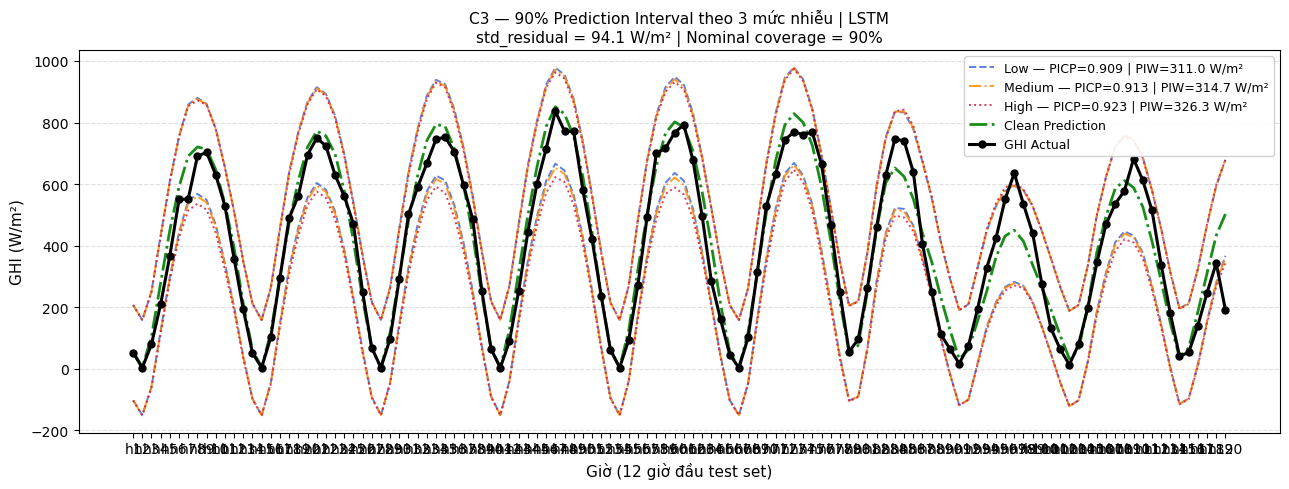

In [32]:
N_HOURS = 120
t = np.arange(N_HOURS)

all_preds_by_level = {}
for level_name, sigmas_plot in NOISE_LEVELS.items():
    preds = []
    for seed in range(N_REPEAT):
        X_noisy_raw = inject_noise(
            X_test, FEATURES, sigmas_plot,
            FEATURE_PROB, FEATURE_CLIP,
            PERTURB_RATE, seed
        )
        X_noisy_sc = scaler.transform(X_noisy_raw)
        ghi_noisy  = predict_ghi_from_noisy(
            ROBUST_MODEL, X_noisy_raw, X_noisy_sc, H0_test
        )
        preds.append(ghi_noisy)
    all_preds_by_level[level_name] = np.array(preds)

# ── Config ───────────────────────────────────────────────────────
level_styles = {
    'low'   : ('royalblue',  '--'),
    'medium': ('darkorange', '-.'),
    'high'  : ('crimson',    ':' ),
}

fig, ax = plt.subplots(figsize=(13, 5))

for level_name, (color, ls) in level_styles.items():
    ap  = all_preds_by_level[level_name]
    r   = exp_results[list(NOISE_LEVELS.keys()).index(level_name)]

    ghi_mean_lv  = np.mean(ap, axis=0)
    std_input_lv = np.std(ap,  axis=0)
    std_total_lv = np.sqrt(std_input_lv[:N_HOURS]**2 + std_residual**2)

    lower_c3 = ghi_mean_lv[:N_HOURS] - 1.645 * std_total_lv
    upper_c3 = ghi_mean_lv[:N_HOURS] + 1.645 * std_total_lv

    # Vẽ 2 đường biên interval
    ax.plot(t, lower_c3, color=color, linewidth=1.4, linestyle=ls, alpha=0.85)
    ax.plot(t, upper_c3, color=color, linewidth=1.4, linestyle=ls, alpha=0.85,
            label=(f'{level_name.capitalize()} — '
                   f'PICP={r["PICP_C3"]:.3f} | PIW={r["PIW_C3"]:.1f} W/m²'))

# Clean prediction
ax.plot(t, ghi_clean[:N_HOURS],
        color='green', linewidth=2.0, linestyle='-.', alpha=0.9,
        label='Clean Prediction')

# Ground truth
ax.plot(t, ghi_true[:N_HOURS],
        color='black', linewidth=2.2, marker='o', markersize=5,
        label='GHI Actual')

# ── Formatting ───────────────────────────────────────────────────
ax.set_xlabel('Giờ (12 giờ đầu test set)', fontsize=11)
ax.set_ylabel('GHI (W/m²)', fontsize=11)
ax.set_title(
    f'C3 — 90% Prediction Interval theo 3 mức nhiễu | {ROBUST_MODEL}\n'
    f'std_residual = {std_residual:.1f} W/m² | Nominal coverage = 90%',
    fontsize=11
)
ax.set_xticks(t)
ax.set_xticklabels([f'h{i+1}' for i in t])
ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [33]:
from scipy import stats

stat, p = stats.shapiro(residuals_val[:500])  # Shapiro-Wilk
skew    = stats.skew(residuals_val)
kurt    = stats.kurtosis(residuals_val)

print(f"Shapiro p-value : {p:.4f}  ({'Normal ✅' if p > 0.05 else 'NOT Normal ⚠️'})")
print(f"Skewness        : {skew:.4f}")
print(f"Kurtosis        : {kurt:.4f}")

Shapiro p-value : 0.0000  (NOT Normal ⚠️)
Skewness        : -0.5715
Kurtosis        : 1.7959


In [ ]:
# ── C3: Locally Weighted Conformal Prediction (Hour + SZA) ───────
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

ALPHA       = 0.10
K_NEIGHBORS = 25

# ── Lấy (hour, SZA) từ val và test ──────────────────────────────
hour_col = FEATURES.index('hour_sin')   # dùng hour_sin, hour_cos

# Dùng hour_sin, hour_cos, SZA → 3 chiều
# hour_sin/cos giữ tính cyclic (23h gần 0h)
hour_sin_col = FEATURES.index('hour_sin')
hour_cos_col = FEATURES.index('hour_cos')

cond_val  = np.column_stack([
    X_val[:, hour_sin_col],
    X_val[:, hour_cos_col],
])   # shape: (n_val, 2)

cond_test = np.column_stack([
    X_test[:, hour_sin_col],
    X_test[:, hour_cos_col],
])   # shape: (n_test, 2)

if ROBUST_MODEL == 'LSTM':
    cond_val  = cond_val[WINDOW:]
    cond_test = cond_test[WINDOW:]

# ── Scale để 3 chiều có đơn vị tương đương ───────────────────────
# hour_sin/cos đã trong [-1,1], trong [0,90] → cần scale
scaler_cond = StandardScaler()
cond_val_sc  = scaler_cond.fit_transform(cond_val)
cond_test_sc = scaler_cond.transform(cond_test)

# ── Fit KNN trên (hour_sin, hour_cos, SZA) val ───────────────────
knn = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric='euclidean')
knn.fit(cond_val_sc)

distances, indices = knn.kneighbors(cond_test_sc)
# indices shape: (n_test, K_NEIGHBORS)

# ── Residual của MLP trên val set (reuse từ C3 Prep) ─────────────
if ROBUST_MODEL == 'LSTM':
    residuals_val_cf = GHI_val[WINDOW:] - ghi_val_pred
else:
    residuals_val_cf = GHI_val - ghi_val_pred

# ── Tính interval per-sample ─────────────────────────────────────
lower_cf = np.zeros(len(cond_test_sc))
upper_cf = np.zeros(len(cond_test_sc))

for i in range(len(cond_test_sc)):
    neighbor_residuals = residuals_val_cf[indices[i]]   # (K,)
    q_lo_i = np.quantile(neighbor_residuals, ALPHA / 2)
    q_hi_i = np.quantile(neighbor_residuals, 1 - ALPHA / 2)

    lower_cf[i] = ghi_clean[i] + q_lo_i
    upper_cf[i] = ghi_clean[i] + q_hi_i

# ── Tích hợp noise uncertainty từ C2 ─────────────────────────────
print("══ C3 Conformal (Hour ) — Per-Sample Interval ══\n")

for level_name in NOISE_LEVELS:
    ap           = all_preds_by_level[level_name]
    std_input_lv = np.std(ap, axis=0)

    lower_c3_cf = lower_cf - std_input_lv
    upper_c3_cf = upper_cf + std_input_lv

    picp_cf = np.mean((ghi_true >= lower_c3_cf) & (ghi_true <= upper_c3_cf))
    piw_cf  = np.mean(upper_c3_cf - lower_c3_cf)

    width_cf   = upper_c3_cf - lower_c3_cf
    pen_lo     = (2 / ALPHA) * np.maximum(lower_c3_cf - ghi_true, 0)
    pen_hi     = (2 / ALPHA) * np.maximum(ghi_true - upper_c3_cf, 0)
    winkler_cf = np.mean(width_cf + pen_lo + pen_hi)

    print(f"[{level_name:6s}] PICP={picp_cf:.3f} | "
          f"PIW={piw_cf:.1f} W/m² | "
          f"Winkler={winkler_cf:.2f}")

# ── Clean (không có noise) ────────────────────────────────────────
picp_clean_cf = np.mean((ghi_true >= lower_cf) & (ghi_true <= upper_cf))
piw_clean_cf  = np.mean(upper_cf - lower_cf)
print(f"\n[clean ] PICP={picp_clean_cf:.3f} | PIW={piw_clean_cf:.1f} W/m²")

# ── Coverage theo giờ ─────────────────────────────────────────────
print("\n── Coverage theo giờ (clean interval) ──")
test_mask = (df_fe['datetime_vn'] >= '2025-09-01')
test_hours = df_fe.loc[test_mask, 'hour'].values
if ROBUST_MODEL == 'LSTM':
    test_hours = test_hours[WINDOW:]

for h in sorted(set(test_hours)):
    mask_h  = (test_hours == h)
    covered = ((ghi_true[mask_h] >= lower_cf[mask_h]) &
               (ghi_true[mask_h] <= upper_cf[mask_h]))
    print(f"  Hour {h:02d} | PICP={covered.mean():.3f} | "
          f"PIW={np.mean(upper_cf[mask_h]-lower_cf[mask_h]):.1f} W/m² | "
          f"n={mask_h.sum()}")

IndexError: index 1394 is out of bounds for axis 0 with size 1394

In [36]:
# ── Cài đặt + import SHAP ───────────────────────────────────────
try:
    import shap
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'])
    import shap
print('shap version:', shap.__version__)

shap version: 0.51.0


In [37]:
# ── Chọn model tốt nhất + tính SHAP values ──────────────────────
BEST_MODEL = ghi_df.iloc[0]['Model']          # model GHI RMSE thấp nhất
print(f'\U0001F50D Giải thích model: {BEST_MODEL}')

_model_map = {
    'Ridge'       : (lr_tuned,    'scaled'),
    'RandomForest': (rf_tuned,    'raw'),
    'XGBoost'     : (xgb_tuned,   'raw'),
    'MLP'         : (mlp_tuned,   'scaled'),
    'LSTM'        : (lstm_model,  'lstm'),
}
assert BEST_MODEL in _model_map, f'Model {BEST_MODEL} chưa được map!'
best_est, input_type = _model_map[BEST_MODEL]
rng_shap = np.random.default_rng(RANDOM_STATE)

if input_type == 'lstm':
    # GradientExplainer trên chuỗi (window, n_feat)
    bg_idx    = rng_shap.choice(len(X_train_seq),
                                size=min(100, len(X_train_seq)), replace=False)
    explainer = shap.GradientExplainer(best_est, X_train_seq[bg_idx])
    n_expl    = min(300, len(X_test_seq))
    sv_raw    = np.array(explainer.shap_values(X_test_seq[:n_expl])).squeeze()  # (n, win, feat)
    sv        = sv_raw.mean(axis=1)              # gộp timestep → (n, feat)
    X_expl    = X_test_seq[:n_expl].mean(axis=1)
    base_val  = float(np.mean(best_est.predict(X_test_seq[:n_expl], verbose=0)))
else:
    X_bg   = X_train_sc if input_type == 'scaled' else X_train
    X_full = X_test_sc  if input_type == 'scaled' else X_test

    if BEST_MODEL in ('RandomForest', 'XGBoost'):
        explainer = shap.TreeExplainer(best_est)
        n_expl    = min(2000, len(X_full))
        X_expl    = X_full[:n_expl]
        sv        = np.asarray(explainer.shap_values(X_expl))
        base_val  = float(np.array(explainer.expected_value).flatten()[0])

    elif BEST_MODEL == 'Ridge':
        explainer = shap.LinearExplainer(best_est, X_bg)
        n_expl    = min(2000, len(X_full))
        X_expl    = X_full[:n_expl]
        sv        = np.asarray(explainer.shap_values(X_expl))
        base_val  = float(np.array(explainer.expected_value).flatten()[0])

    else:  # MLP → KernelExplainer (chậm → giới hạn mẫu)
        bg        = shap.sample(X_bg, 100, random_state=RANDOM_STATE)
        explainer = shap.KernelExplainer(best_est.predict, bg)
        n_expl    = min(300, len(X_full))
        X_expl    = X_full[:n_expl]
        sv        = np.asarray(explainer.shap_values(X_expl, nsamples=100))
        base_val  = float(np.array(explainer.expected_value).flatten()[0])

print(f'SHAP values shape : {sv.shape}')
print(f'Số mẫu giải thích : {n_expl}')
print(f'Base value (E[K_T]): {base_val:.4f}')

# Bảng tầm quan trọng trung bình |SHAP|
imp = (pd.DataFrame({'Feature': FEATURES, 'mean_|SHAP|': np.abs(sv).mean(axis=0)})
         .sort_values('mean_|SHAP|', ascending=False).reset_index(drop=True))
print('\n══ Feature importance (mean |SHAP|) ══')
print(imp.to_string(index=False))

🔍 Giải thích model: LSTM
SHAP values shape : (300, 12)
Số mẫu giải thích : 300
Base value (E[K_T]): 0.4262

══ Feature importance (mean |SHAP|) ══
          Feature  mean_|SHAP|
CLRSKY_SFC_SW_DWN     0.010039
         hour_sin     0.005672
             RH2M     0.005060
         hour_cos     0.004244
               H0     0.004132
        month_sin     0.003928
              T2M     0.003347
              SZA     0.003280
      PRECTOTCORR     0.002311
            WS10M     0.001698
        month_cos     0.000661
              day     0.000479


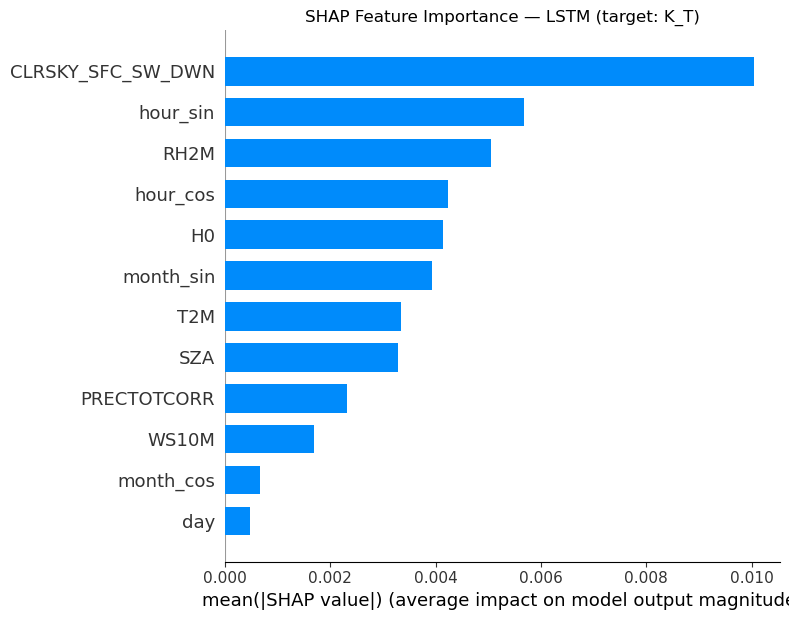

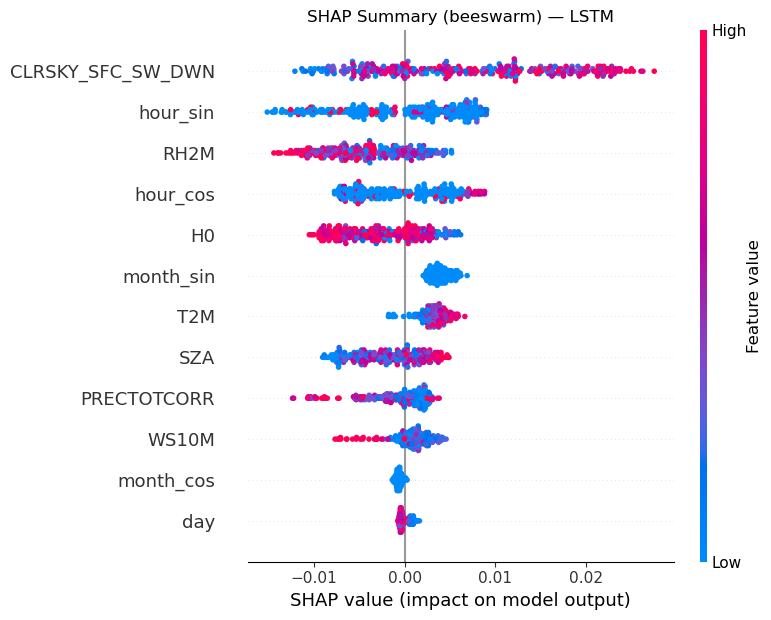

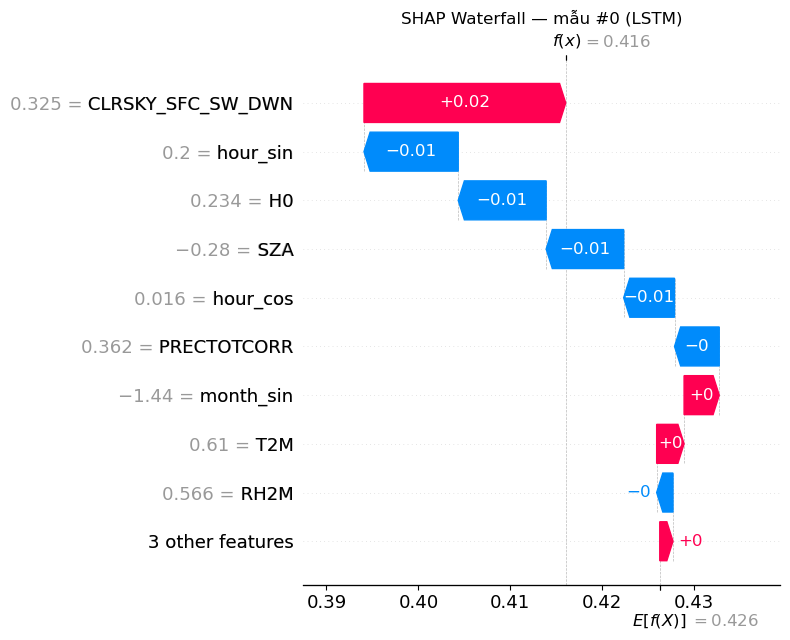

In [38]:
# ── Visualize SHAP ──────────────────────────────────────────────
# 1) Bar — global feature importance
shap.summary_plot(sv, X_expl, feature_names=FEATURES,
                  plot_type='bar', show=False)
plt.title(f'SHAP Feature Importance — {BEST_MODEL} (target: K_T)')
plt.tight_layout(); plt.show()

# 2) Beeswarm — chiều & phân bố ảnh hưởng từng feature
shap.summary_plot(sv, X_expl, feature_names=FEATURES, show=False)
plt.title(f'SHAP Summary (beeswarm) — {BEST_MODEL}')
plt.tight_layout(); plt.show()

# 3) Waterfall — giải thích 1 dự đoán đơn lẻ (mẫu đầu test)
expl_one = shap.Explanation(
    values        = sv[0],
    base_values   = base_val,
    data          = X_expl[0],
    feature_names = FEATURES,
)
shap.plots.waterfall(expl_one, show=False)
plt.title(f'SHAP Waterfall — mẫu #0 ({BEST_MODEL})')
plt.tight_layout(); plt.show()